# Function Visualization

Notebook tạo các interactive visualization (Plotly) và export thành HTML độc lập cho GitHub Pages.

> 📊 GitHub chỉ hiển thị **ảnh tĩnh** của biểu đồ (GitHub không chạy JavaScript). Xem bản **tương tác**: [Linear Function](https://tlh222k.github.io/ai-from-scratch/visualizations/linear_function.html) · [Quadratic Function](https://tlh222k.github.io/ai-from-scratch/visualizations/quadratic_function.html)

**Chạy bằng `Restart Kernel → Run All`.** Output: `visualizations/linear_function.html`, `quadratic_function.html`, `index.html`.

# Import libraries

In [1]:
import sys
import numpy as np
import plotly
import plotly.graph_objects as go
import plotly.io as pio

from pathlib import Path
from IPython.display import display, HTML

print("=" * 50)
print("FUNCTION VISUALIZATION")
print("=" * 50)

print(f"Python: {sys.version.split()[0]}")
print(f"Python executable: {sys.executable}")
print(f"NumPy: {np.__version__}")
print(f"Plotly: {plotly.__version__}")

FUNCTION VISUALIZATION
Python: 3.13.18
Python executable: /usr/local/bin/python3
NumPy: 2.5.3
Plotly: 7.1.0


# Configure project

In [2]:
def find_project_root(start_path=None):
    """
    Find the root directory of ai-from-scratch.

    The project root must contain:
        - phases/
        - visualizations/
    """

    current_path = Path(start_path or Path.cwd()).resolve()

    for path in [current_path, *current_path.parents]:

        has_phases = (path / "phases").is_dir()
        has_visualizations = (path / "visualizations").is_dir()

        if has_phases and has_visualizations:
            return path

    raise FileNotFoundError(
        "Cannot find project root. "
        "Expected 'phases/' and 'visualizations/' directories."
    )


# Detect project root
PROJECT_ROOT = find_project_root()

# Define directories
VISUALIZATION_DIR = PROJECT_ROOT / "visualizations"

NOTEBOOK_DIR = VISUALIZATION_DIR / "notebooks"

# Create directories if they do not exist
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)


print("Project root:", PROJECT_ROOT)
print("Visualization directory:", VISUALIZATION_DIR)
print("Notebook directory:", NOTEBOOK_DIR)

Project root: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch
Visualization directory: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations
Notebook directory: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/notebooks


# Configure rendering (Jupyter + GitHub)

Output gồm **cả hai**: `application/vnd.plotly.v1+json` (tương tác trong Jupyter/VS Code) và `image/png` (ảnh tĩnh để GitHub hiển thị). Cần `pip install kaleido`.

In [3]:
# Interactive in Jupyter/VS Code + static PNG fallback for GitHub
pio.renderers.default = "plotly_mimetype+png"

GITHUB_USER = "tlh222k"
REPO_NAME = "ai-from-scratch"

PAGES_BASE = f"https://{GITHUB_USER}.github.io/{REPO_NAME}/visualizations"

print("Renderer:", pio.renderers.default)
print("Pages base URL:", PAGES_BASE)

Renderer: plotly_mimetype+png
Pages base URL: https://tlh222k.github.io/ai-from-scratch/visualizations


# Create reusable figure configuration

Chỉ định nghĩa **một** lần `configure_figure()` (bản đầy đủ tham số). Trước đây hàm này bị định nghĩa hai lần nên bản thứ hai (thiếu `xaxis_title`, `yaxis_title`) ghi đè bản đầu.

In [4]:
def configure_figure(
    fig,
    title,
    xaxis_title="x",
    yaxis_title="y",
    height=520
):
    """
    Configure common Plotly figure settings.

    Parameters
    ----------
    fig : go.Figure
        Plotly figure.

    title : str
        Figure title.

    xaxis_title : str
        X-axis label.

    yaxis_title : str
        Y-axis label.

    height : int
        Figure height in pixels.
    """

    fig.update_layout(
        title={
            "text": title,
            "x": 0.5,
            "xanchor": "center",
            "font": {
                "size": 22
            }
        },

        autosize=True,
        height=height,

        margin=dict(
            l=60,
            r=30,
            t=110,   # room for title + horizontal legend
            b=60
        ),

        template="plotly_white",

        font=dict(
            family="Arial, sans-serif",
            size=14
        ),

        hovermode="closest",

        xaxis_title=xaxis_title,
        yaxis_title=yaxis_title,

        xaxis=dict(
            showgrid=True,
            zeroline=True,
            zerolinewidth=2,
            zerolinecolor="#64748b"
        ),

        yaxis=dict(
            showgrid=True,
            zeroline=True,
            zerolinewidth=2,
            zerolinecolor="#64748b"
        ),

        legend=dict(
            orientation="h",
            yanchor="bottom",
            y=1.02,
            xanchor="center",
            x=0.5
        )
    )

    return fig

# Create reusable caption function

In [5]:
def build_caption_html(
    caption,
    title=None,
    font_size="16px"
):
    """
    Generate reusable HTML caption.

    The caption accepts trusted HTML and LaTeX.
    """

    title_html = ""

    if title:

        title_html = f"""
        <h3 class="caption-title">
            {title}
        </h3>
        """

    return f"""
    <div class="visualization-caption">

        {title_html}

        <div class="caption-content">
            {caption}
        </div>

    </div>

    <style>

        .visualization-caption {{
            width: 100%;
            box-sizing: border-box;

            margin-top: 16px;
            padding: 18px 22px;

            background: #f8fafc;

            border-left: 4px solid #2563eb;
            border-radius: 8px;

            font-size: {font_size};
            line-height: 1.8;

            color: #334155;

            overflow-wrap: break-word;
        }}

        .caption-title {{
            margin: 0 0 10px 0;

            font-size: 20px;
            font-weight: 700;

            color: #0f172a;
        }}

        .caption-content strong {{
            color: #1d4ed8;
        }}

        @media (max-width: 600px) {{

            .visualization-caption {{
                padding: 14px;
                font-size: 14px;
            }}

            .caption-title {{
                font-size: 17px;
            }}

        }}

    </style>
    """


def add_caption(
    fig,
    caption,
    title=None,
    font_size="16px",
    html_name=None
):
    """
    Display Plotly figure with HTML caption in Jupyter.

    Output contains interactive JSON + static PNG (shown by GitHub).
    If html_name is given, a link to the interactive GitHub Pages
    version is displayed below the figure.
    """

    fig.show()

    if html_name:
        display(HTML(
            f'<p>🔗 <a href="{PAGES_BASE}/{html_name}" target="_blank">'
            f'Open the interactive version</a> (GitHub Pages)</p>'
        ))

    caption_html = build_caption_html(
        caption=caption,
        title=title,
        font_size=font_size
    )

    display(HTML(caption_html))

# Export responsive HTML

- Plotly.js được nhúng trực tiếp (`include_plotlyjs=True`) nên biểu đồ chạy **offline**.
- MathJax tải qua CDN → **cần Internet** để render công thức LaTeX (biểu đồ vẫn hoạt động nếu offline).

In [6]:
def export_figure(
    fig,
    filename,
    caption,
    caption_title=None,
    page_title=None,
    font_size="16px"
):
    """
    Export Plotly figure and HTML caption
    into a standalone responsive HTML file.

    Plotly.js is embedded locally in the HTML (works offline).
    MathJax is loaded through CDN (Internet required for formulas).
    """

    output_path = VISUALIZATION_DIR / filename

    # Generate Plotly HTML
    plot_html = fig.to_html(
        full_html=False,

        include_plotlyjs=True,

        config={
            "responsive": True,
            "displaylogo": False,
            "scrollZoom": True
        }
    )

    # Generate caption HTML
    caption_html = build_caption_html(
        caption=caption,
        title=caption_title,
        font_size=font_size
    )

    document_title = page_title or caption_title or filename

    # Combine everything into one HTML document
    # NOTE: the string must start with <!DOCTYPE html> (no leading
    # whitespace) so browsers never fall back to quirks mode.
    html_document = f"""<!DOCTYPE html>
<html lang="en">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>{document_title}</title>

    <!-- MathJax config: \\( ... \\) inline, \\[ ... \\] display -->
    <script>
        window.MathJax = {{
            tex: {{
                inlineMath: [['\\\\(', '\\\\)']],
                displayMath: [['\\\\[', '\\\\]']]
            }}
        }};
    </script>

    <!-- MathJax is loaded from a CDN: Internet is required to render formulas -->
    <script
        id="MathJax-script"
        async
        src="https://cdn.jsdelivr.net/npm/mathjax@3/es5/tex-chtml.js">
    </script>

    <style>

        * {{
            box-sizing: border-box;
        }}

        body {{
            margin: 0;
            padding: 24px;

            font-family: Arial, sans-serif;

            background: #ffffff;
            color: #1e293b;
        }}

        .container {{
            width: 100%;
            max-width: 1100px;

            margin: 0 auto;
        }}

        .back-link {{
            display: inline-block;
            margin-bottom: 12px;

            color: #2563eb;
            text-decoration: none;
            font-size: 14px;
        }}

        .back-link:hover {{
            text-decoration: underline;
        }}

        .plot-container {{
            width: 100%;
        }}

        .note {{
            margin-top: 12px;

            color: #94a3b8;
            font-size: 12px;
            text-align: center;
        }}

        @media (max-width: 600px) {{

            body {{
                padding: 10px;
            }}

        }}

    </style>

</head>

<body>

    <main class="container">

        <a class="back-link" href="./index.html">&larr; All visualizations</a>

        <section class="plot-container">

            {plot_html}

        </section>

        <section>

            {caption_html}

        </section>

        <p class="note">
            Math formulas are rendered with MathJax and need an Internet connection.
            The interactive chart works offline.
        </p>

    </main>

</body>

</html>
"""

    # Write HTML file
    output_path.write_text(
        html_document,
        encoding="utf-8"
    )

    size_kb = output_path.stat().st_size / 1024

    print(f"Exported successfully: {output_path}")
    print(f"File size: {size_kb:.2f} KB")

    return output_path

# Define the linear function

In [7]:
def linear_function(x):
    """
    Linear function: f(x) = 2x + 1
    """
    return 2 * x + 1


# Generate input values
x_linear = np.linspace(-10, 10, 200)

# Calculate output values
y_linear = linear_function(x_linear)


print("Linear Function: f(x) = 2x + 1")
print("Number of data points:", len(x_linear))

Linear Function: f(x) = 2x + 1
Number of data points: 200


# Create Linear Function visualization

In [8]:
fig_linear = go.Figure()


# Add linear function
fig_linear.add_trace(
    go.Scatter(

        x=x_linear,
        y=y_linear,

        mode="lines",

        name="f(x) = 2x + 1",

        line=dict(
            width=3
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "f(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Add y-intercept
fig_linear.add_trace(
    go.Scatter(

        x=[0],
        y=[1],

        mode="markers",

        name="Y-intercept (0, 1)",

        marker=dict(
            size=11,
            symbol="circle"
        ),

        hovertemplate=(
            "Y-intercept<br>"
            "(%{x}, %{y})"
            "<extra></extra>"
        )

    )
)


# Configure figure (displayed together with its caption in the next cell)
fig_linear = configure_figure(
    fig=fig_linear,

    title="Linear Function: f(x) = 2x + 1",

    xaxis_title="Input (x)",

    yaxis_title="Output f(x)"
)

# Add Linear Function caption

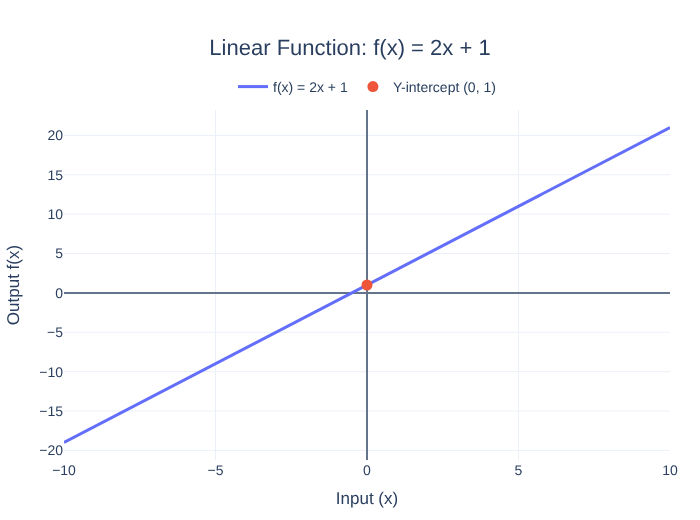

In [9]:
linear_caption = r"""
A <strong>linear function</strong> has the form \(f(x)=mx+b\).
Here, \(f(x)=2x+1\), and its graph is a straight line.

<br><br>

The <strong>slope</strong> is \(m=2\).

This means that whenever \(x\) increases by 1 unit,
the output \(f(x)\) increases by 2 units.

<br><br>

The <strong>y-intercept</strong> is \(b=1\).

Therefore, the line crosses the y-axis at:

\[
(0,1)
\]

<br>

<strong>Why is the graph a straight line?</strong>

Because the rate of change is constant:

\[
\frac{f(x+1)-f(x)}{1}=2
\]

for every value of \(x\). A constant rate of change always
produces a straight line.
"""


add_caption(
    fig=fig_linear,

    caption=linear_caption,

    title="Understanding the Linear Function",

    html_name="linear_function.html"
)

# Export Linear Function

In [10]:
export_figure(
    fig=fig_linear,

    filename="linear_function.html",

    caption=linear_caption,

    caption_title="Understanding the Linear Function",

    page_title="Linear Function - AI From Scratch"
)

Exported successfully: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/linear_function.html
File size: 4719.28 KB


PosixPath('/tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/linear_function.html')

# Define the quadratic function

In [11]:
def quadratic_function(x):
    """
    Quadratic function: g(x) = x²
    """
    return x ** 2


# Generate input values
x_quadratic = np.linspace(-5, 5, 300)

# Calculate output values
y_quadratic = quadratic_function(x_quadratic)


# Explicit data points (computed from the function, not hard-coded)
x_points = np.array([-2, -1, 0, 1, 2])

y_points = quadratic_function(x_points)

assert list(y_points) == [4, 1, 0, 1, 4]


print("Quadratic Function: g(x) = x²")

print("\nData points:")

for x, y in zip(x_points, y_points):

    print(f"({x}, {y})")

Quadratic Function: g(x) = x²

Data points:
(-2, 4)
(-1, 1)
(0, 0)
(1, 1)
(2, 4)


# Create Quadratic Function visualization

In [12]:
fig_quadratic = go.Figure()


# Add quadratic function
fig_quadratic.add_trace(
    go.Scatter(

        x=x_quadratic,
        y=y_quadratic,

        mode="lines",

        name="g(x) = x²",

        line=dict(
            width=3
        ),

        hovertemplate=(
            "x = %{x:.2f}<br>"
            "g(x) = %{y:.2f}"
            "<extra></extra>"
        )

    )
)


# Add explicit data points
fig_quadratic.add_trace(
    go.Scatter(

        x=x_points,
        y=y_points,

        mode="markers",

        name="Data points",

        marker=dict(
            size=11,
            symbol="circle",
            line=dict(
                width=1
            )
        ),

        hovertemplate=(
            "Point: (%{x}, %{y})"
            "<extra></extra>"
        )

    )
)


# Configure figure (displayed together with its caption in the next cell)
fig_quadratic = configure_figure(
    fig=fig_quadratic,

    title="Quadratic Function: g(x) = x²",

    xaxis_title="Input (x)",

    yaxis_title="Output g(x)"
)

# Add Quadratic Function caption

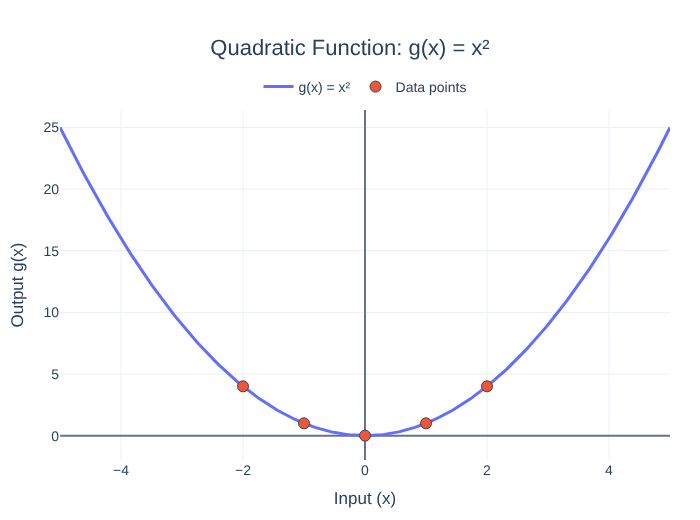

In [13]:
quadratic_caption = r"""
A <strong>quadratic function</strong> has the form
\(g(x)=ax^2+bx+c\) with \(a\neq 0\).
Here, \(g(x)=x^2\), and its graph is a parabola that opens upward.

<br><br>

The <strong>vertex</strong> is located at:

\[
(0,0)
\]

This is the minimum point of the function.

<br><br>

The graph is <strong>symmetric about the y-axis</strong>,
because \(g(-x)=(-x)^2=x^2=g(x)\).

For example:

\[
g(-2)=(-2)^2=4
\]

\[
g(2)=2^2=4
\]

Therefore:

\[
g(-2)=g(2)
\]

Squaring removes the sign of the input, so opposite inputs
give the same output.

<br><br>

<strong>Highlighted data points:</strong>

\[
(-2,4),\;(-1,1),\;(0,0),\;(1,1),\;(2,4)
\]

<br>

<strong>Linear vs. quadratic:</strong>

A linear function such as \(f(x)=2x+1\) has a constant rate of
change and its graph is a straight line. A quadratic function has a
changing rate of change (the slope of \(x^2\) is \(2x\)),
so its graph curves into a parabola.
"""


add_caption(
    fig=fig_quadratic,

    caption=quadratic_caption,

    title="Understanding the Quadratic Function",

    html_name="quadratic_function.html"
)

# Export Quadratic Function

In [14]:
export_figure(
    fig=fig_quadratic,

    filename="quadratic_function.html",

    caption=quadratic_caption,

    caption_title="Understanding the Quadratic Function",

    page_title="Quadratic Function - AI From Scratch"
)

Exported successfully: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/quadratic_function.html
File size: 4722.31 KB


PosixPath('/tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/quadratic_function.html')

# Create index.html

In [15]:
index_html = """<!DOCTYPE html>
<html lang="en">

<head>

    <meta charset="UTF-8">

    <meta name="viewport"
          content="width=device-width, initial-scale=1.0">

    <title>AI From Scratch - Visualizations</title>

    <style>

        * {
            box-sizing: border-box;
        }

        body {
            margin: 0;
            padding: 40px 20px;

            font-family: Arial, sans-serif;

            background: #f8fafc;
            color: #1e293b;
        }

        .container {
            width: 100%;
            max-width: 900px;

            margin: 0 auto;
        }

        header {
            text-align: center;
            margin-bottom: 40px;
        }

        header h1 {
            font-size: 32px;
            margin-bottom: 10px;
        }

        header p {
            color: #64748b;
            line-height: 1.7;
        }

        .card {
            display: block;

            padding: 24px;
            margin-bottom: 20px;

            background: white;

            border: 1px solid #e2e8f0;
            border-radius: 12px;

            text-decoration: none;
            color: inherit;

            transition: transform 0.2s;
        }

        .card:hover {
            transform: translateY(-4px);
            border-color: #2563eb;
        }

        .card h2 {
            margin-top: 0;
            color: #2563eb;
        }

        .card p {
            color: #64748b;
            line-height: 1.6;
        }

        footer {
            margin-top: 40px;
            text-align: center;
            color: #94a3b8;
            font-size: 13px;
        }

        @media (max-width: 600px) {

            body {
                padding: 24px 14px;
            }

            header h1 {
                font-size: 25px;
            }

        }

    </style>

</head>

<body>

    <main class="container">

        <header>

            <h1>AI From Scratch</h1>

            <p>
                Interactive visualizations for
                Mathematics, Machine Learning
                and Deep Learning.
            </p>

        </header>


        <section>

            <a class="card"
               href="./linear_function.html">

                <h2>Linear Function</h2>

                <p>
                    Explore the linear function
                    f(x) = 2x + 1: slope, y-intercept
                    and constant rate of change.
                </p>

            </a>


            <a class="card"
               href="./quadratic_function.html">

                <h2>Quadratic Function</h2>

                <p>
                    Explore the quadratic function
                    g(x) = x&sup2;: vertex, symmetry
                    and highlighted data points.
                </p>

            </a>

        </section>


        <footer>

            AI From Scratch - Interactive Learning Resources<br>
            Math formulas on each page need an Internet connection (MathJax CDN).

        </footer>

    </main>

</body>

</html>
"""


index_path = VISUALIZATION_DIR / "index.html"

index_path.write_text(
    index_html,
    encoding="utf-8"
)

print("Homepage created:", index_path)

Homepage created: /tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/index.html


# Check output files

Kiểm tra file tồn tại, có nội dung hợp lệ, và link trong `index.html` trỏ đúng file.

In [16]:
import re

expected_files = [
    "index.html",
    "linear_function.html",
    "quadratic_function.html"
]


print("=" * 55)
print("VISUALIZATION EXPORT REPORT")
print("=" * 55)

all_ok = True

for filename in expected_files:

    file_path = VISUALIZATION_DIR / filename

    if file_path.exists():

        size_kb = file_path.stat().st_size / 1024

        print(f"[SUCCESS] {filename}")
        print(f"          Size: {size_kb:.2f} KB")

    else:

        all_ok = False
        print(f"[FAILED] {filename}")


# Content checks for the chart pages
for filename in ["linear_function.html", "quadratic_function.html"]:

    text = (VISUALIZATION_DIR / filename).read_text(encoding="utf-8")

    checks = {
        "doctype": text.startswith("<!DOCTYPE html>"),
        "plotly.js embedded": "plotly.js" in text and len(text) > 1_000_000,
        "plot div": 'class="plotly-graph-div"' in text,
        "caption": 'class="visualization-caption"' in text,
        "MathJax": "mathjax@3" in text,
    }

    for name, ok in checks.items():

        all_ok = all_ok and ok
        print(f"  {filename}: {name:<20} {'OK' if ok else 'MISSING'}")


# Link checks for index.html
index_text = (VISUALIZATION_DIR / "index.html").read_text(encoding="utf-8")

for href in re.findall(r'href="([^"]+)"', index_text):

    target = (VISUALIZATION_DIR / href).resolve()
    ok = target.is_file()

    all_ok = all_ok and ok
    print(f"  index.html link {href:<28} {'OK' if ok else 'BROKEN'}")


print("=" * 55)
print("All checks passed." if all_ok else "Some checks FAILED.")

assert all_ok, "Export validation failed"

VISUALIZATION EXPORT REPORT
[SUCCESS] index.html
          Size: 2.95 KB
[SUCCESS] linear_function.html
          Size: 4719.28 KB
[SUCCESS] quadratic_function.html
          Size: 4722.31 KB
  linear_function.html: doctype              OK
  linear_function.html: plotly.js embedded   OK
  linear_function.html: plot div             OK
  linear_function.html: caption              OK
  linear_function.html: MathJax              OK
  quadratic_function.html: doctype              OK
  quadratic_function.html: plotly.js embedded   OK
  quadratic_function.html: plot div             OK
  quadratic_function.html: caption              OK
  quadratic_function.html: MathJax              OK
  index.html link ./linear_function.html       OK
  index.html link ./quadratic_function.html    OK
All checks passed.


# Open visualization locally

Mở file HTML đã export bằng trình duyệt mặc định (an toàn hơn `IFrame` với đường dẫn tương đối, vốn phụ thuộc vào Jupyter server root). Đặt `OPEN_IN_BROWSER = True` để mở.

In [17]:
import webbrowser

OPEN_IN_BROWSER = False

index_uri = (VISUALIZATION_DIR / "index.html").as_uri()

print("Local preview:", index_uri)

if OPEN_IN_BROWSER:
    webbrowser.open(index_uri)

Local preview: file:///tmp/claude-0/-home-claude/c62f9c70-8577-5f03-b289-4077dacce0e1/scratchpad/repo/ai-from-scratch/visualizations/index.html
